<a href="https://colab.research.google.com/github/rokeya160210/Skin-Cancer-2-papers-comparison/blob/main/01_cohort_provenance_and_overlap_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Derm7pt cohort provenance and HAM10000 ↔ Derm7pt overlap audit

**Answers reviewer points #3 and #4. It also supplies the lesion statistics used in the reply to #2.**

| Section | Reviewer point | Output file (in `OUT_DIR`) |
|---|---|---|
| A | #2: HAM10000 image vs lesion counts; leakage in the *old* image-level splits | `ham10000_lesion_stats.json`, `old_split_leakage.csv` |
| B | #4: full Derm7pt diagnosis → label mapping, exclusion counts, case IDs, test order | `derm7pt_mapping_table.csv`, `derm7pt_cohort_full.csv`, `derm7pt_test_cohort_963.csv` |
| C | #3: exact byte hash, decoded-pixel hash, perceptual hash (8 flips/rotations, full + centre-crop), ImageNet-embedding similarity | `overlap_candidates.csv`, `overlap_summary.json` |
| D | #3: positive controls (planted near-duplicates), so the audit's sensitivity is measured, not assumed | `overlap_positive_controls.csv` |
| E | #3: automatic duplicate decision (optional manual override) and the **final independent N** | `overlap_review.csv`, `final_test_cohort.csv` |

**Runs on CPU** (Kaggle or Colab). A GPU only speeds up the embedding step in C4.

**Decision thresholds, fixed before the audit is run:**
* perceptual-hash candidate: Hamming distance ≤ `PHASH_MAX_HAMMING` (8 of 64 bits) for *any* of the 8 dihedral variants, full image or centre crop;
* embedding candidate: cosine similarity ≥ `EMBED_MIN_COSINE` (0.95);
* **automatic duplicate decision** (Section E, no manual step): a pair is a duplicate if (i) the files or the decoded pixels are identical, or (ii) **both** detectors independently point to the **same** HAM10000 image (pHash ≤ 8 bits **and** cosine ≥ 0.95). A pair flagged by only one detector is listed and shown, but not excluded. Dermoscopy images all look alike to an ImageNet network, so the cosine screen alone flags many unrelated pairs;
* optional manual override: type `duplicate` or `not_duplicate` in the `reviewer_decision` column of `overlap_review.csv` and re-run Section E. Blank cells keep the automatic decision.

Section D reports how many planted near-duplicates these thresholds catch. Quote that recall in the paper.

In [1]:
# ============================== CONFIG ======================================
import os, sys, json, glob, hashlib, subprocess, time
def _in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False
IN_COLAB = _in_colab()
# Colab can also have an (empty) /kaggle/input folder, so Kaggle is detected by its own environment variable.
IN_KAGGLE = (not IN_COLAB) and bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE"))
print("Environment:", "Colab" if IN_COLAB else ("Kaggle" if IN_KAGGLE else "local"))
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/audit"     # notebook 03 reads derm7pt_test_cohort_963.csv from here
elif IN_KAGGLE:
    OUT_DIR = "/kaggle/working/audit"            # Kaggle: download this folder and upload it to MyDrive/audit
else:
    OUT_DIR = os.path.abspath("audit")
os.makedirs(OUT_DIR, exist_ok=True)

PHASH_MAX_HAMMING = 8        # pre-declared (bits out of 64)
EMBED_MIN_COSINE  = 0.95     # pre-declared
INCLUDE_CLINIC_IMAGES = False  # Derm7pt clinical photos are not used in the paper; set True to audit them too
N_POSITIVE_CONTROLS = 50     # planted near-duplicates for Section D
RNG_SEED = 2026

# Exactly the mapping used by the training notebooks (first matching rule wins).
DERM7PT_DIAG_TO_CLASS = [("melanoma", "MEL"), ("nevus", "NV"), ("basal cell carcinoma", "BCC"),
                         ("seborrheic keratosis", "BKL"), ("dermatofibroma", "DF"), ("vascular", "VASC")]
COMMON_CLASSES = ["MEL", "NV", "BCC", "BKL", "DF", "VASC"]
EXPECTED_TEST_ORDER_FINGERPRINT = "bba3ea9a777c1eb1"   # value recorded in every run manifest

# Optional, Section A3: folders holding the OLD image-level train_split.csv / val_split.csv files.
# Leave EMPTY (recommended): the old splits are then rebuilt exactly from their seeds and verified by fingerprint.
OLD_SPLIT_DIRS = {
    # "seed42":    "/content/drive/MyDrive/skin_ablation/runs/controlled/seed42/results",
    # "seed1000":  "/content/drive/MyDrive/skin_ablation/runs/controlled/seed1000/results",
    # "seed50000": "/content/drive/MyDrive/skin_ablation/runs/controlled/seed50000/results",
}
print("OUT_DIR:", OUT_DIR)

Environment: Colab
Mounted at /content/drive
OUT_DIR: /content/drive/MyDrive/audit


In [2]:
# ---- dependencies -----------------------------------------------------------
def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)
try:
    import imagehash
except ImportError:
    _pip("imagehash"); import imagehash
import numpy as np, pandas as pd
from PIL import Image, ImageOps
print("numpy", np.__version__, "| pandas", pd.__version__, "| imagehash", imagehash.__version__)

numpy 2.1.3 | pandas 2.2.3 | imagehash 4.3.2


In [3]:
# ---- locate the two datasets (Kaggle input or kagglehub cache) -------------
def _find(filename, roots):
    hits = []
    for r in roots:
        if r and os.path.isdir(r):
            for dp, dns, fs in os.walk(r):
                dns.sort()
                if filename in fs:
                    hits.append(os.path.join(dp, filename))
    return sorted(set(hits))

def locate_datasets():
    """Use attached Kaggle inputs if they really contain the data; otherwise download with kagglehub."""
    roots = [r for r in ["/kaggle/input"] if os.path.isdir(r)]
    need = {"kmader/skin-cancer-mnist-ham10000": "HAM10000_metadata.csv", "menakamohanakumar/derm7pt": "meta.csv"}
    for slug, marker in need.items():
        if not _find(marker, roots):
            try:
                import kagglehub
            except ImportError:
                subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True); import kagglehub
            p = kagglehub.dataset_download(slug)
            print(f"downloaded {slug} -> {p}")
            roots.append(p)
    ham = _find("HAM10000_metadata.csv", roots)
    derm = [p for p in _find("meta.csv", roots) if "derm7pt" in p.lower() or "release_v0" in p]
    if not ham or not derm:
        for r in roots:
            print("searched:", r, "->", sorted(os.listdir(r))[:20] if os.path.isdir(r) else "missing")
        raise FileNotFoundError("HAM10000_metadata.csv or Derm7pt meta.csv not found -- see the folders listed above.")
    return roots, ham[0], derm[0]

roots, ham_meta_path, derm_meta_path = locate_datasets()
print("HAM10000 metadata:", ham_meta_path)
print("Derm7pt meta     :", derm_meta_path)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
downloaded kmader/skin-cancer-mnist-ham10000 -> /kaggle/input/skin-cancer-mnist-ham10000
Using Colab cache for faster access to the 'derm7pt' dataset.
downloaded menakamohanakumar/derm7pt -> /kaggle/input/derm7pt
HAM10000 metadata: /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
Derm7pt meta     : /kaggle/input/derm7pt/release_v0/meta/meta.csv


## A. HAM10000: images versus lesions (#2)

In [4]:
ham = pd.read_csv(ham_meta_path)
ham_root = os.path.dirname(ham_meta_path)

# The Kaggle mirror contains the image folders twice (upper- and lower-case names).
# Index by image_id so every image is counted exactly once.
ham_index = {}
for dp, dns, fs in os.walk(ham_root):
    dns.sort()
    for f in sorted(fs):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            ham_index.setdefault(os.path.splitext(f)[0], os.path.join(dp, f))
ham["path"] = ham["image_id"].map(ham_index)
assert ham["path"].notna().all(), "some HAM10000 images not found"
assert ham["image_id"].is_unique

# every lesion must carry a single diagnosis, otherwise a lesion-level stratified split is ill-defined
dx_per_lesion = ham.groupby("lesion_id")["dx"].nunique()
assert (dx_per_lesion == 1).all(), "a lesion_id has more than one dx"

six = ham[ham["dx"] != "akiec"]
imgs_per_lesion = six.groupby("lesion_id").size()
stats = {
    "ham_images_all": int(len(ham)),
    "ham_lesions_all": int(ham["lesion_id"].nunique()),
    "six_class_images": int(len(six)),
    "six_class_lesions": int(six["lesion_id"].nunique()),
    "akiec_images_removed": int((ham["dx"] == "akiec").sum()),
    "six_class_lesions_with_>1_image": int((imgs_per_lesion > 1).sum()),
    "six_class_images_in_multi_image_lesions": int(imgs_per_lesion[imgs_per_lesion > 1].sum()),
    "max_images_per_lesion": int(imgs_per_lesion.max()),
    "per_class": {dx: {"images": int((six["dx"] == dx).sum()),
                       "lesions": int(six.loc[six["dx"] == dx, "lesion_id"].nunique())}
                  for dx in ["mel", "nv", "bcc", "bkl", "df", "vasc"]},
}
json.dump(stats, open(os.path.join(OUT_DIR, "ham10000_lesion_stats.json"), "w"), indent=2)
print(json.dumps(stats, indent=2))

{
  "ham_images_all": 10015,
  "ham_lesions_all": 7470,
  "six_class_images": 9688,
  "six_class_lesions": 7242,
  "akiec_images_removed": 327,
  "six_class_lesions_with_>1_image": 1879,
  "six_class_images_in_multi_image_lesions": 4325,
  "max_images_per_lesion": 6,
  "per_class": {
    "mel": {
      "images": 1113,
      "lesions": 614
    },
    "nv": {
      "images": 6705,
      "lesions": 5403
    },
    "bcc": {
      "images": 514,
      "lesions": 327
    },
    "bkl": {
      "images": 1099,
      "lesions": 727
    },
    "df": {
      "images": 115,
      "lesions": 73
    },
    "vasc": {
      "images": 142,
      "lesions": 98
    }
  }
}


### A3. Same-lesion leakage in the *old* image-level 90/10 splits

This quantifies the problem behind point #2 for the runs reported in the submitted manuscript. **No old files are needed.** The old split was produced only by `train_test_split(test_size=0.10, random_state=SEED, stratify=label)` on the six-class HAM10000 table, so it is rebuilt here exactly as the old notebook built it. The rebuild is accepted only if its training-split fingerprint equals the fingerprint recorded in the old run manifest and quoted in the manuscript (Section IV-H). If you still have the old `train_split.csv` / `val_split.csv`, you can instead point `OLD_SPLIT_DIRS` (CONFIG) at them.

In [5]:
from sklearn.model_selection import train_test_split
OLD_FINGERPRINTS = {42: "04197d64181f5916", 1000: "761fe971fc51c831", 50000: "60abdde42cedd061"}   # manuscript, Sec. IV-H
OLD_CLASS_TO_IDX = {"mel": 0, "nv": 1, "bcc": 2, "bkl": 3, "df": 4, "vasc": 5}   # label coding used by the old notebook
id2lesion = dict(zip(ham["image_id"], ham["lesion_id"]))

def leakage_row(tag, train_ids, val_ids, how):
    tr_les = {id2lesion[i] for i in train_ids}
    va_les = pd.Series([id2lesion[i] for i in val_ids])
    leaked = va_les.isin(tr_les)
    return {"split": tag, "source": how, "n_train": len(train_ids), "n_val": len(val_ids),
            "val_images_whose_lesion_is_in_train": int(leaked.sum()),
            "pct_val_images_leaked": round(100 * leaked.mean(), 2),
            "val_lesions": int(va_les.nunique()), "val_lesions_also_in_train": int(va_les[leaked].nunique())}

rows = []
stem = lambda p: os.path.splitext(os.path.basename(str(p)))[0]
if OLD_SPLIT_DIRS:                                   # option 1: the old CSV files
    for tag, d in OLD_SPLIT_DIRS.items():
        tr_p, va_p = os.path.join(d, "train_split.csv"), os.path.join(d, "val_split.csv")
        if os.path.isfile(tr_p) and os.path.isfile(va_p):
            rows.append(leakage_row(tag, list(pd.read_csv(tr_p)["path"].map(stem)),
                                    list(pd.read_csv(va_p)["path"].map(stem)), "old CSV files"))
        else:
            print(f"{tag}: CSV files not found in {d}")
else:                                                # option 2: exact rebuild (no old files needed)
    old_pool = ham[ham["dx"].isin(OLD_CLASS_TO_IDX)].reset_index(drop=True)   # metadata order, as in the old notebook
    old_pool["label"] = old_pool["dx"].map(OLD_CLASS_TO_IDX).astype(int)
    assert len(old_pool) == 9688
    for seed, fp_expected in OLD_FINGERPRINTS.items():
        tr, va = train_test_split(old_pool, test_size=0.10, random_state=seed, stratify=old_pool["label"])
        fp = hashlib.sha256("|".join(sorted(os.path.basename(p) for p in tr["path"])).encode()).hexdigest()[:16]
        ok = fp == fp_expected
        print(f"seed {seed}: rebuilt fingerprint {fp} | manuscript {fp_expected} | {'MATCH' if ok else 'NO MATCH'}")
        if ok:
            rows.append(leakage_row(f"seed{seed}", list(tr["image_id"]), list(va["image_id"]), "exact rebuild (fingerprint verified)"))
        else:
            print("   -> not reported: the rebuild differs from the old split (e.g. a different scikit-learn version).")
if rows:
    leak = pd.DataFrame(rows); print(leak.to_string(index=False))
    leak.to_csv(os.path.join(OUT_DIR, "old_split_leakage.csv"), index=False)
else:
    print("No verified old split -- leakage not reported.")

seed 42: rebuilt fingerprint 04197d64181f5916 | manuscript 04197d64181f5916 | MATCH
seed 1000: rebuilt fingerprint 761fe971fc51c831 | manuscript 761fe971fc51c831 | MATCH
seed 50000: rebuilt fingerprint 60abdde42cedd061 | manuscript 60abdde42cedd061 | MATCH
    split                               source  n_train  n_val  val_images_whose_lesion_is_in_train  pct_val_images_leaked  val_lesions  val_lesions_also_in_train
   seed42 exact rebuild (fingerprint verified)     8719    969                                  392                  40.45          940                        378
 seed1000 exact rebuild (fingerprint verified)     8719    969                                  390                  40.25          941                        379
seed50000 exact rebuild (fingerprint verified)     8719    969                                  415                  42.83          928                        390


## B. Derm7pt six-class cohort: mapping, exclusions, IDs (#4)

The training notebooks map Derm7pt with a case-insensitive substring rule (first match wins). The EViT notebook uses an equivalent rule written differently (`startswith("melanoma")`, `"basal cell" in`). Both are applied below, and the notebook **asserts that they assign every row identically**.

In [6]:
derm = pd.read_csv(derm_meta_path)
derm_meta_dir = os.path.dirname(derm_meta_path)
derm_release = os.path.dirname(derm_meta_dir)
derm_img_dir = os.path.join(derm_release, "images")
print("Derm7pt columns:", list(derm.columns))
print("rows in meta.csv:", len(derm))

def map_ensemble(diag):                      # == training notebooks
    d = str(diag).lower()
    for key, cls in DERM7PT_DIAG_TO_CLASS:
        if key in d:
            return cls
    return None

def map_evit(dx):                            # == EViT notebook (map_derm7pt_label)
    d = str(dx).strip().lower()
    if d.startswith("melanoma"): return "MEL"
    if "nevus" in d: return "NV"
    if "basal cell" in d: return "BCC"
    if "seborrheic keratosis" in d: return "BKL"
    if "dermatofibroma" in d: return "DF"
    if "vascular" in d: return "VASC"
    return None

derm["meta_row"] = np.arange(len(derm))          # original row index in meta.csv
derm["class_ensemble"] = derm["diagnosis"].map(map_ensemble)
derm["class_evit"] = derm["diagnosis"].map(map_evit)
same = (derm["class_ensemble"].fillna("-") == derm["class_evit"].fillna("-"))
assert same.all(), derm.loc[~same, ["diagnosis", "class_ensemble", "class_evit"]]
print("Ensemble and EViT mappings agree on all", len(derm), "rows.")

def resolve(rel):
    p = os.path.join(derm_img_dir, str(rel))
    return p if os.path.isfile(p) else None
derm["derm_path"] = derm["derm"].map(resolve)
print("dermoscopic images resolved:", derm["derm_path"].notna().sum(), "/", len(derm))

Derm7pt columns: ['case_num', 'diagnosis', 'seven_point_score', 'pigment_network', 'streaks', 'pigmentation', 'regression_structures', 'dots_and_globules', 'blue_whitish_veil', 'vascular_structures', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management', 'clinic', 'derm', 'case_id', 'notes']
rows in meta.csv: 1011
Ensemble and EViT mappings agree on all 1011 rows.
dermoscopic images resolved: 1011 / 1011


In [7]:
# ---- mapping table: every raw diagnosis string -> class, with counts --------
mt = (derm.groupby("diagnosis", dropna=False)
          .agg(images=("meta_row", "size"), mapped_class=("class_ensemble", "first"))
          .reset_index().sort_values(["mapped_class", "diagnosis"], na_position="last"))
mt["mapped_class"] = mt["mapped_class"].fillna("EXCLUDED (no rule matches)")
mt.to_csv(os.path.join(OUT_DIR, "derm7pt_mapping_table.csv"), index=False)
print(mt.to_string(index=False))
print("\nPer class:", derm["class_ensemble"].value_counts().to_dict())
print("Excluded:", derm.loc[derm["class_ensemble"].isna(), "diagnosis"].value_counts().to_dict())

                   diagnosis  images               mapped_class
        basal cell carcinoma      42                        BCC
        seborrheic keratosis      45                        BKL
              dermatofibroma      20                         DF
                    melanoma       1                        MEL
   melanoma (0.76 to 1.5 mm)      53                        MEL
          melanoma (in situ)      64                        MEL
melanoma (less than 0.76 mm)     102                        MEL
 melanoma (more than 1.5 mm)      28                        MEL
         melanoma metastasis       4                        MEL
                  blue nevus      28                         NV
                 clark nevus     399                         NV
              combined nevus      13                         NV
            congenital nevus      17                         NV
                dermal nevus      33                         NV
             recurrent nevus       6    

In [8]:
# ---- rebuild the test cohort exactly as the training notebooks did ---------
#      (rows with a resolvable dermoscopic image and a mapped label, meta.csv order)
cohort = derm[derm["derm_path"].notna() & derm["class_ensemble"].notna()].reset_index(drop=True)
cohort["test_position"] = np.arange(len(cohort))
cohort["label_index"] = cohort["class_ensemble"].map({c: i for i, c in enumerate(COMMON_CLASSES)})
cohort["derm_file"] = cohort["derm_path"].map(os.path.basename)

fp = hashlib.sha256("|".join(cohort["derm_file"]).encode()).hexdigest()[:16]
print("N =", len(cohort), "| test-order fingerprint:", fp)
assert fp == EXPECTED_TEST_ORDER_FINGERPRINT, "Test order differs from the one used in the runs!"
print("Fingerprint matches the run manifests -> this is the exact cohort, in the exact order, that was scored.")

# lesion / patient structure of the test cohort (relevant to #14)
id_col = "case_num" if "case_num" in cohort.columns else None
print("\nOne dermoscopic image per row:", cohort["derm"].is_unique)
if id_col:
    print(f"'{id_col}' unique across the cohort:", cohort[id_col].is_unique)
print("Columns that could identify a patient:",
      [c for c in derm.columns if "patient" in c.lower()] or "none in meta.csv")

keep = [c for c in ["test_position", "meta_row", "case_num", "derm", "derm_file", "clinic", "diagnosis",
                    "class_ensemble", "label_index", "level_of_diagnostic_difficulty", "elevation",
                    "location", "sex", "management", "seven_point_score"] if c in cohort.columns]
cohort[keep].to_csv(os.path.join(OUT_DIR, "derm7pt_test_cohort_963.csv"), index=False)
derm.drop(columns=["derm_path"]).to_csv(os.path.join(OUT_DIR, "derm7pt_cohort_full.csv"), index=False)
print("\nSaved derm7pt_test_cohort_963.csv (ordered test IDs) and derm7pt_cohort_full.csv")

# official Derm7pt split membership (for information only; the paper uses all mapped cases)
for name in ["train_indexes.csv", "valid_indexes.csv", "test_indexes.csv"]:
    p = os.path.join(derm_meta_dir, name)
    if os.path.isfile(p):
        idx = set(pd.read_csv(p).iloc[:, 0].astype(int))
        print(f"{name}: {len(idx)} rows; of the {len(cohort)} test images, "
              f"{cohort['meta_row'].isin(idx).sum()} are in it")

N = 963 | test-order fingerprint: bba3ea9a777c1eb1
Fingerprint matches the run manifests -> this is the exact cohort, in the exact order, that was scored.

One dermoscopic image per row: True
'case_num' unique across the cohort: True
Columns that could identify a patient: none in meta.csv

Saved derm7pt_test_cohort_963.csv (ordered test IDs) and derm7pt_cohort_full.csv
train_indexes.csv: 413 rows; of the 963 test images, 396 are in it
valid_indexes.csv: 203 rows; of the 963 test images, 192 are in it
test_indexes.csv: 395 rows; of the 963 test images, 375 are in it


## C. Cross-dataset overlap audit (#3)

The pool searched is **all 10,015 HAM10000 images** (AKIEC included, since a duplicate of any HAM image would break independence) against **all Derm7pt dermoscopic images** (1,011 rows). The 963-image subset is marked.

1. **Exact byte hash** (SHA-256 of the file).
2. **Decoded-pixel hash** (SHA-256 of the RGB array). This catches identical pixels stored in different containers.
3. **Perceptual hash** (pHash, 64 bits) on the full image and on a centre square crop. Derm7pt queries use all 8 flips/rotations. This catches resized, recompressed, flipped or rotated copies.
4. **ImageNet-embedding cosine similarity** (ResNet50, global average pool). This catches crops and colour changes that hashing misses.

In [9]:
from concurrent.futures import ThreadPoolExecutor

ham_files = ham[["image_id", "path"]].rename(columns={"image_id": "id"}).assign(src="HAM10000")
ham_files["in_963"] = False
dq = derm[derm["derm_path"].notna()][["meta_row", "derm_path", "derm"]].copy()
dq["id"] = "derm:" + dq["derm"].astype(str)
dq = dq.rename(columns={"derm_path": "path"})
dq["in_963"] = dq["meta_row"].isin(cohort["meta_row"])
derm_files = dq[["id", "path", "in_963"]].assign(src="Derm7pt-derm")
if INCLUDE_CLINIC_IMAGES and "clinic" in derm.columns:
    cl = derm[["meta_row", "clinic"]].copy(); cl["path"] = cl["clinic"].map(resolve)
    cl = cl[cl["path"].notna()]; cl["id"] = "clinic:" + cl["clinic"].astype(str); cl["in_963"] = False
    derm_files = pd.concat([derm_files, cl[["id", "path", "in_963"]].assign(src="Derm7pt-clinic")])
print("HAM10000 files:", len(ham_files), "| Derm7pt files:", len(derm_files))

def sha_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for ch in iter(lambda: f.read(1 << 20), b""): h.update(ch)
    return h.hexdigest()

def square_crop(im):
    w, h = im.size; s = min(w, h)
    return im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))

DIHEDRAL = [lambda im: im, lambda im: im.rotate(90, expand=True), lambda im: im.rotate(180, expand=True),
            lambda im: im.rotate(270, expand=True), ImageOps.mirror, lambda im: ImageOps.mirror(im).rotate(90, expand=True),
            lambda im: ImageOps.mirror(im).rotate(180, expand=True), lambda im: ImageOps.mirror(im).rotate(270, expand=True)]

def ph(im):
    return int(str(imagehash.phash(im, hash_size=8)), 16)

def describe(path, all_variants):
    im = Image.open(path).convert("RGB")
    arr = np.asarray(im)
    out = {"sha_file": sha_file(path),
           "sha_pixels": hashlib.sha256(arr.tobytes() + str(arr.shape).encode()).hexdigest(),
           "w": im.size[0], "h": im.size[1]}
    variants = DIHEDRAL if all_variants else DIHEDRAL[:1]
    out["ph_full"] = [ph(t(im)) for t in variants]
    out["ph_crop"] = [ph(t(square_crop(im))) for t in variants]
    return out

def run(df, all_variants):
    with ThreadPoolExecutor(max_workers=os.cpu_count() or 4) as ex:
        res = list(ex.map(lambda p: describe(p, all_variants), df["path"]))
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(res)], axis=1)

t0 = time.time()
H = run(ham_files, all_variants=False)
D = run(derm_files, all_variants=True)
print(f"hashed {len(H)} + {len(D)} images in {time.time()-t0:.0f}s")

HAM10000 files: 10015 | Derm7pt files: 1011
hashed 10015 + 1011 images in 50s


In [10]:
# ---- C1/C2: exact matches -------------------------------------------------
exact_file = D.merge(H, on="sha_file", suffixes=("_derm", "_ham"))
exact_pix = D.merge(H, on="sha_pixels", suffixes=("_derm", "_ham"))
print("Exact byte-identical pairs   :", len(exact_file))
print("Identical decoded-pixel pairs:", len(exact_pix))

# within-Derm7pt exact duplicates (information)
dup_in_derm = D[D.duplicated("sha_pixels", keep=False)].sort_values("sha_pixels")
print("Within-Derm7pt identical-pixel files:", len(dup_in_derm))

# ---- C3: perceptual hash, min Hamming distance over variants ---------------
_POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def popcount64(x):
    return _POP[x.view(np.uint8).reshape(-1, 8)].sum(1)

def min_hamming(query_variants, ref):          # query_variants: list[int]; ref: np.uint64 array
    best = np.full(len(ref), 64, dtype=np.int32)
    for q in query_variants:
        best = np.minimum(best, popcount64(np.bitwise_xor(ref, np.uint64(q))))
    return best

ref_full = np.array([v[0] for v in H["ph_full"]], dtype=np.uint64)
ref_crop = np.array([v[0] for v in H["ph_crop"]], dtype=np.uint64)
rows = []
for i, r in D.iterrows():
    d_full = min_hamming(r["ph_full"], ref_full)
    d_crop = min_hamming(r["ph_crop"], ref_crop)
    d = np.minimum(d_full, d_crop)
    j = int(np.argmin(d))
    rows.append({"derm_id": r["id"], "in_963": r["in_963"], "nearest_ham": H.at[j, "id"],
                 "phash_min_hamming": int(d[j]), "phash_full": int(d_full[j]), "phash_crop": int(d_crop[j]),
                 "n_ham_within_threshold": int((d <= PHASH_MAX_HAMMING).sum())})
PH = pd.DataFrame(rows)
print("\npHash nearest-neighbour distance (bits) over all Derm7pt images:")
print(PH["phash_min_hamming"].describe().round(2).to_string())
print(f"Derm7pt images with >=1 HAM10000 image within {PHASH_MAX_HAMMING} bits:",
      int((PH["phash_min_hamming"] <= PHASH_MAX_HAMMING).sum()))

Exact byte-identical pairs   : 0
Identical decoded-pixel pairs: 0
Within-Derm7pt identical-pixel files: 0

pHash nearest-neighbour distance (bits) over all Derm7pt images:
count    1011.00
mean       10.29
std         2.75
min         2.00
25%         8.00
50%        10.00
75%        12.00
max        16.00
Derm7pt images with >=1 HAM10000 image within 8 bits: 314


In [11]:
# ---- C4: ImageNet embedding similarity (ResNet50, avg-pool, L2-normalised) --
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
emb_model = ResNet50(include_top=False, weights="imagenet", pooling="avg", input_shape=(224, 224, 3))

def load_224(p):
    im = Image.open(p).convert("RGB").resize((224, 224), Image.BILINEAR)
    return np.asarray(im, dtype=np.float32)

def embed(paths, bs=64):
    out = []
    for k in range(0, len(paths), bs):
        x = np.stack([load_224(p) for p in paths[k:k + bs]])
        e = emb_model.predict(preprocess_input(x), verbose=0)
        out.append(e / np.linalg.norm(e, axis=1, keepdims=True))
    return np.concatenate(out)

t0 = time.time()
EH = embed(list(H["path"])); ED = embed(list(D["path"]))
print(f"embedded in {time.time()-t0:.0f}s")

# also query with horizontally flipped Derm7pt images
def embed_flipped(paths, bs=64):
    out = []
    for k in range(0, len(paths), bs):
        x = np.stack([load_224(p)[:, ::-1, :] for p in paths[k:k + bs]])
        e = emb_model.predict(preprocess_input(x), verbose=0)
        out.append(e / np.linalg.norm(e, axis=1, keepdims=True))
    return np.concatenate(out)
EDflip = embed_flipped(list(D["path"]))
S = np.maximum(ED @ EH.T, EDflip @ EH.T)
PH["nearest_ham_by_embedding"] = H["id"].values[S.argmax(1)]
PH["embed_max_cosine"] = S.max(1).round(4)
print("Max cosine similarity per Derm7pt image:")
print(PH["embed_max_cosine"].describe().round(4).to_string())
print(f"Derm7pt images with cosine >= {EMBED_MIN_COSINE}:", int((PH["embed_max_cosine"] >= EMBED_MIN_COSINE).sum()))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
embedded in 148s
Max cosine similarity per Derm7pt image:
count    1011.0000
mean        0.6999
std         0.0938
min         0.4379
25%         0.6307
50%         0.6982
75%         0.7651
max         0.9331
Derm7pt images with cosine >= 0.95: 0


In [12]:
# ---- candidate list ---------------------------------------------------------
PH["exact_file_match"] = PH["derm_id"].isin(exact_file["id_derm"])
PH["exact_pixel_match"] = PH["derm_id"].isin(exact_pix["id_derm"])
PH["is_candidate"] = (PH["exact_file_match"] | PH["exact_pixel_match"]
                      | (PH["phash_min_hamming"] <= PHASH_MAX_HAMMING)
                      | (PH["embed_max_cosine"] >= EMBED_MIN_COSINE))
cand = PH[PH["is_candidate"]].sort_values(["embed_max_cosine"], ascending=False)
cand.to_csv(os.path.join(OUT_DIR, "overlap_candidates.csv"), index=False)
PH.to_csv(os.path.join(OUT_DIR, "overlap_all_nearest_neighbours.csv"), index=False)

summary = {
    "ham10000_images_searched": int(len(H)), "derm7pt_images_searched": int(len(D)),
    "exact_byte_pairs": int(len(exact_file)), "exact_pixel_pairs": int(len(exact_pix)),
    "phash_threshold_bits": PHASH_MAX_HAMMING, "embedding_threshold_cosine": EMBED_MIN_COSINE,
    "derm_images_flagged_phash": int((PH["phash_min_hamming"] <= PHASH_MAX_HAMMING).sum()),
    "derm_images_flagged_embedding": int((PH["embed_max_cosine"] >= EMBED_MIN_COSINE).sum()),
    "candidates_total": int(len(cand)), "candidates_in_963": int(cand["in_963"].sum()),
    "within_derm7pt_identical_pixel_files": int(len(dup_in_derm)),
}
json.dump(summary, open(os.path.join(OUT_DIR, "overlap_summary.json"), "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "ham10000_images_searched": 10015,
  "derm7pt_images_searched": 1011,
  "exact_byte_pairs": 0,
  "exact_pixel_pairs": 0,
  "phash_threshold_bits": 8,
  "embedding_threshold_cosine": 0.95,
  "derm_images_flagged_phash": 314,
  "derm_images_flagged_embedding": 0,
  "candidates_total": 314,
  "candidates_in_963": 305,
  "within_derm7pt_identical_pixel_files": 0
}


## D. Positive controls: does the audit actually catch near-duplicates?

`N_POSITIVE_CONTROLS` Derm7pt images are copied in memory and given the edits a re-publication might apply: resize and crop to HAM10000's 600×450 format, JPEG recompression (quality 85), a horizontal flip, and a mild brightness change. Each altered copy is planted among the HAM10000 references. The table reports how many are recovered by each detector at the pre-declared thresholds. Nothing is written to disk except the result table.

In [13]:
from PIL import ImageEnhance
import io
rng = np.random.default_rng(RNG_SEED)
ctrl_idx = rng.choice(len(D), size=min(N_POSITIVE_CONTROLS, len(D)), replace=False)

def to_ham_format(im):                       # crop to 4:3 then resize to 600x450 (HAM10000 geometry)
    w, h = im.size; tw = min(w, int(h * 4 / 3)); th = int(tw * 3 / 4)
    im = im.crop(((w - tw) // 2, (h - th) // 2, (w - tw) // 2 + tw, (h - th) // 2 + th))
    return im.resize((600, 450), Image.BILINEAR)

def perturb(im, kind):
    if kind == "resize_crop": return to_ham_format(im)
    if kind == "jpeg85":
        b = io.BytesIO(); to_ham_format(im).save(b, "JPEG", quality=85); b.seek(0); return Image.open(b).convert("RGB")
    if kind == "hflip": return ImageOps.mirror(to_ham_format(im))
    if kind == "brightness": return ImageEnhance.Brightness(to_ham_format(im)).enhance(1.15)
    raise ValueError(kind)

res = []
for kind in ["resize_crop", "jpeg85", "hflip", "brightness"]:
    hit_ph = hit_em = hit_both = 0; coss = []
    for i in ctrl_idx:
        im = perturb(Image.open(D.at[i, "path"]).convert("RGB"), kind)
        planted_full, planted_crop = np.uint64(ph(im)), np.uint64(ph(square_crop(im)))
        d = min(int(min_hamming(D.at[i, "ph_full"], np.array([planted_full])).min()),
                int(min_hamming(D.at[i, "ph_crop"], np.array([planted_crop])).min()))
        hit_ph += d <= PHASH_MAX_HAMMING
        x = preprocess_input(np.asarray(im.resize((224, 224), Image.BILINEAR), dtype=np.float32)[None])
        e = emb_model.predict(x, verbose=0)[0]; e /= np.linalg.norm(e)
        cos = max(float(ED[i] @ e), float(EDflip[i] @ e))
        hit_em += cos >= EMBED_MIN_COSINE; coss.append(cos)
        hit_both += (d <= PHASH_MAX_HAMMING) and (cos >= EMBED_MIN_COSINE)
    n = len(ctrl_idx)
    res.append({"perturbation": kind, "n": n, "recall_phash": round(hit_ph / n, 3),
                "recall_embedding": round(hit_em / n, 3), "recall_both_detectors": round(hit_both / n, 3),
                "min_cosine_planted": round(min(coss), 4)})
pc = pd.DataFrame(res); print(pc.to_string(index=False))
print("\nFor reference, real Derm7pt -> nearest HAM10000 cosine: median",
      round(float(PH["embed_max_cosine"].median()), 4), "| 99th percentile", round(float(PH["embed_max_cosine"].quantile(0.99)), 4))
pc.to_csv(os.path.join(OUT_DIR, "overlap_positive_controls.csv"), index=False)

perturbation  n  recall_phash  recall_embedding  recall_both_detectors  min_cosine_planted
 resize_crop 50           1.0              0.36                   0.36              0.7831
      jpeg85 50           1.0              0.34                   0.34              0.7830
       hflip 50           1.0              0.26                   0.26              0.7800
  brightness 50           1.0              0.18                   0.18              0.8053

For reference, real Derm7pt -> nearest HAM10000 cosine: median 0.6982 | 99th percentile 0.9039


## E. Duplicate decision and the final independent N (runs automatically)

Decision rule, fixed before the audit:

1. **duplicate (identical)**: identical file bytes or identical decoded pixels;
2. **duplicate (both detectors)**: pHash distance ≤ 8 **and** embedding cosine ≥ 0.95, **and** both detectors name the same HAM10000 image;
3. **not duplicate (single detector)**: everything else. These pairs are listed and shown below for transparency, but not excluded.

**Optional manual override:** after looking at the figures, you may type `duplicate` or `not_duplicate` in the `reviewer_decision` column of `overlap_review.csv` (in `OUT_DIR`) and re-run this section. Blank cells keep the automatic decision. Nothing here waits for you, so Run all always finishes.

final_decision
not duplicate (single detector)    314


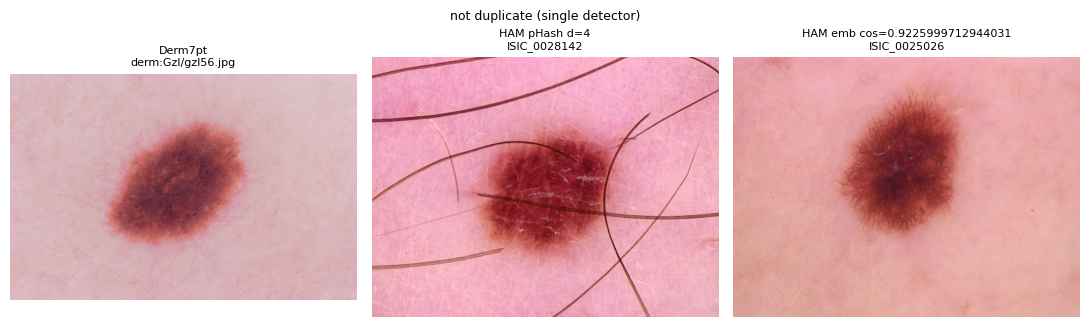

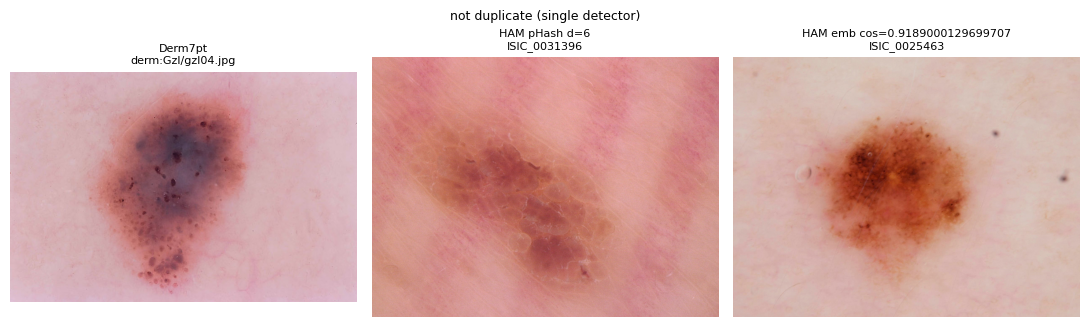

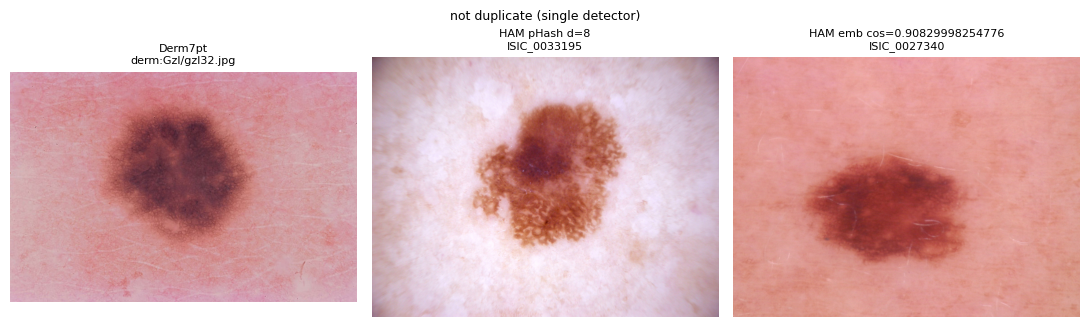

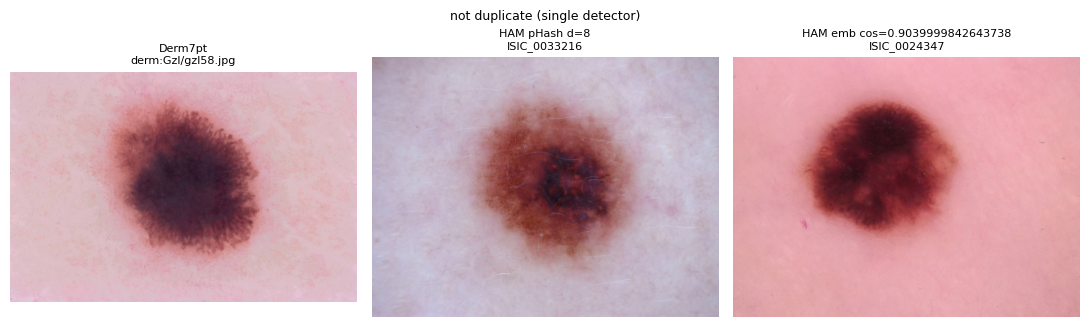

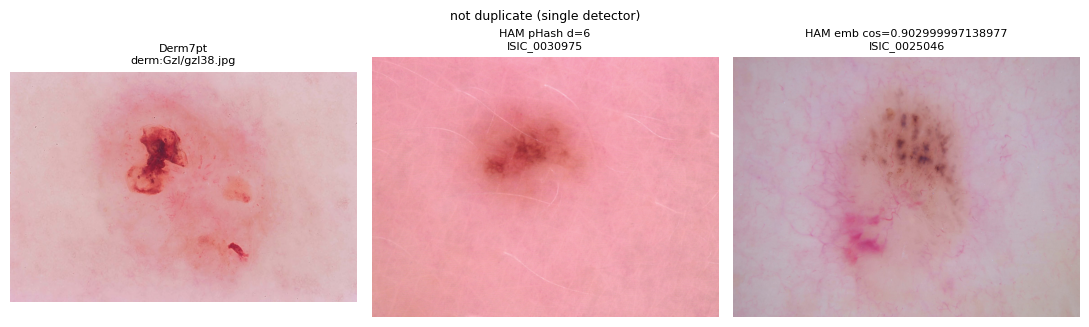

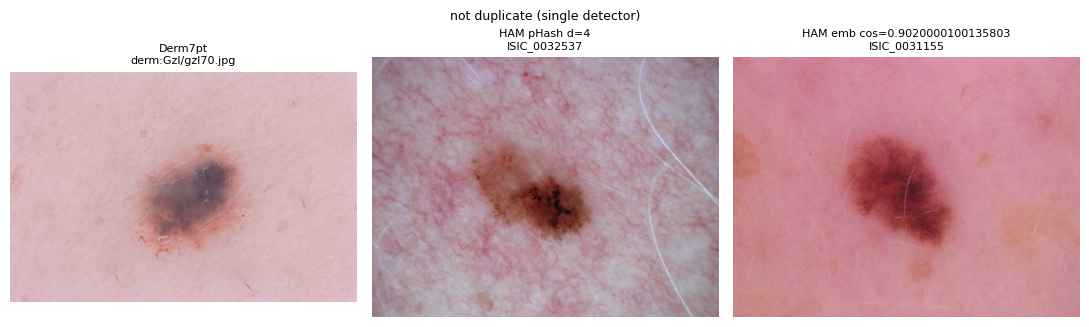

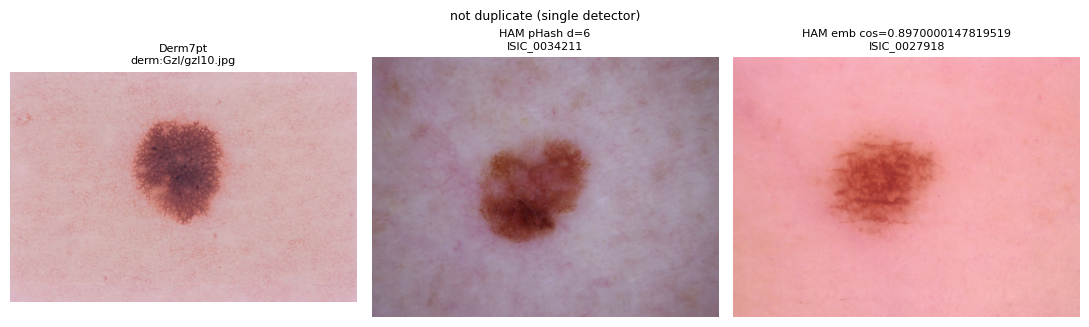

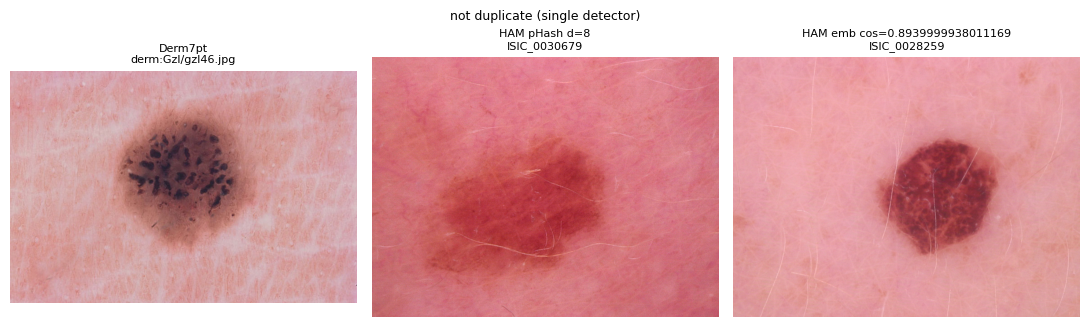

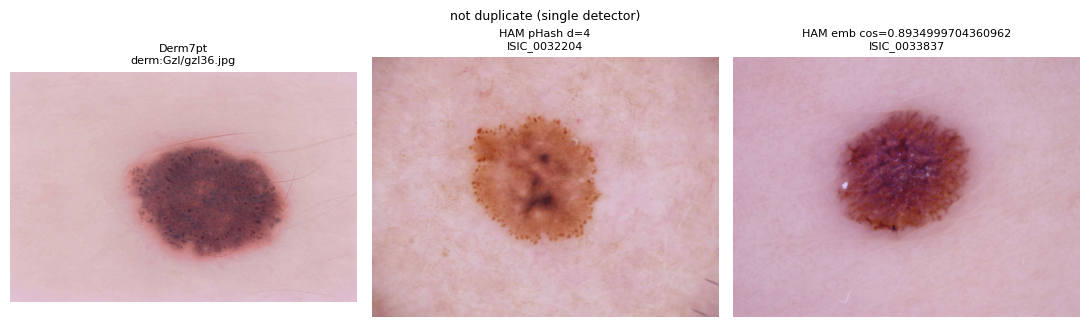

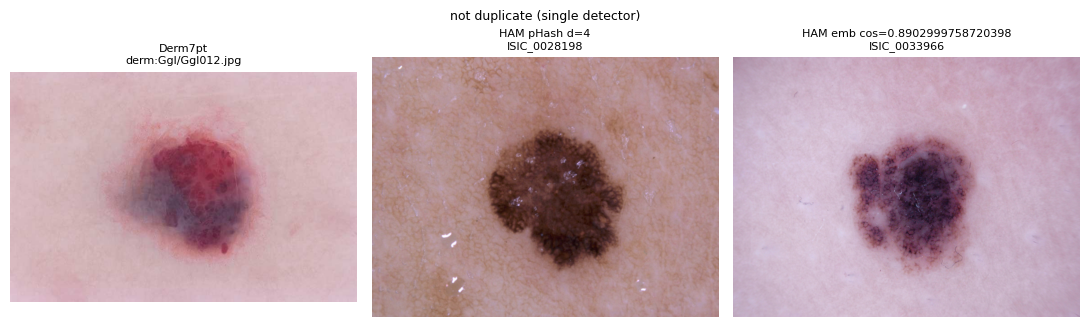

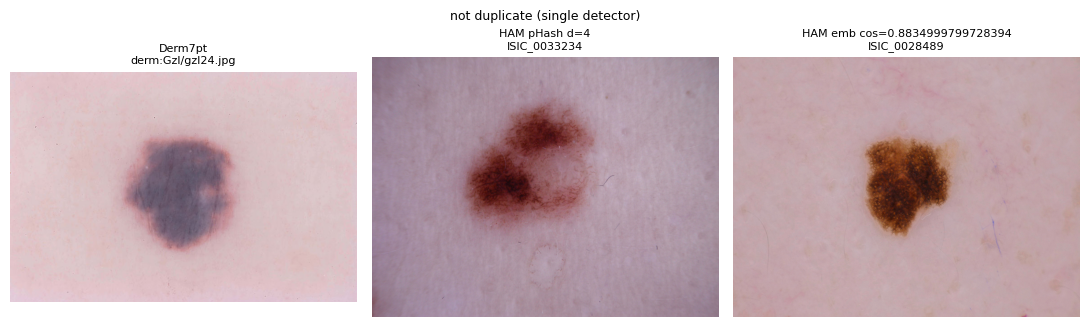

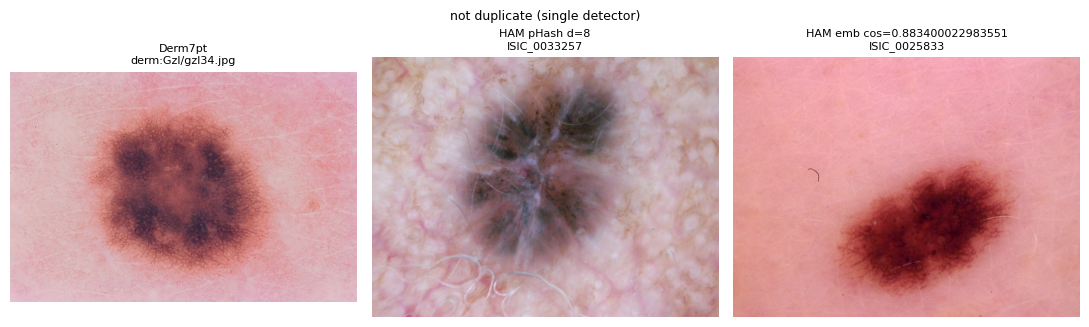

In [14]:
import matplotlib.pyplot as plt
rev_path = os.path.join(OUT_DIR, "overlap_review.csv")
cols = ["derm_id", "in_963", "nearest_ham", "phash_min_hamming", "nearest_ham_by_embedding", "embed_max_cosine",
        "exact_file_match", "exact_pixel_match"]
rv = cand[cols].copy() if len(cand) else pd.DataFrame(columns=cols)
rv["same_ham_image"] = rv["nearest_ham"] == rv["nearest_ham_by_embedding"]
def auto_rule(r):
    if r["exact_file_match"] or r["exact_pixel_match"]:
        return "duplicate (identical)"
    if r["phash_min_hamming"] <= PHASH_MAX_HAMMING and r["embed_max_cosine"] >= EMBED_MIN_COSINE and r["same_ham_image"]:
        return "duplicate (both detectors)"
    return "not duplicate (single detector)"
rv["auto_decision"] = rv.apply(auto_rule, axis=1) if len(rv) else []

# keep any manual decisions already typed into an earlier overlap_review.csv
manual = {}
if os.path.isfile(rev_path):
    old = pd.read_csv(rev_path, dtype=str).fillna("")
    if "reviewer_decision" in old.columns:
        for did, v in zip(old["derm_id"], old["reviewer_decision"]):
            v = v.strip().lower().replace(" ", "_").replace("-", "_")
            if v in ("duplicate", "not_duplicate"):
                manual[did] = v
            elif v not in ("", "not_reviewed", "nan"):
                print(f"ignored unrecognised entry '{v}' for {did} (use duplicate / not_duplicate or leave blank)")
rv["reviewer_decision"] = rv["derm_id"].map(manual).fillna("")
rv["final_decision"] = [("duplicate (manual)" if m == "duplicate" else "not duplicate (manual)") if m else a
                        for m, a in zip(rv["reviewer_decision"], rv["auto_decision"])]
rv["is_duplicate"] = rv["final_decision"].str.startswith("duplicate")
rv = rv.sort_values(["is_duplicate", "embed_max_cosine"], ascending=[False, False]).reset_index(drop=True)
rv.to_csv(rev_path, index=False)
print(rv["final_decision"].value_counts().to_string() if len(rv) else "No candidates at the pre-declared thresholds.")

# figures for your own inspection (not for publication): every pair called a duplicate + the 12 most similar others
id2path = dict(zip(pd.concat([H["id"], D["id"]]), pd.concat([H["path"], D["path"]])))
show = pd.concat([rv[rv["is_duplicate"]], rv[~rv["is_duplicate"]].head(12)])
for _, r in show.iterrows():
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
    for a, k, t in zip(ax, [r["derm_id"], r["nearest_ham"], r["nearest_ham_by_embedding"]],
                       ["Derm7pt", f"HAM pHash d={r['phash_min_hamming']}", f"HAM emb cos={r['embed_max_cosine']}"]):
        a.imshow(Image.open(id2path[k]).convert("RGB")); a.set_title(f"{t}\n{k}", fontsize=8); a.axis("off")
    fig.suptitle(r["final_decision"], fontsize=9); plt.tight_layout(); plt.show()

In [15]:
# ---- final independent cohort ----------------------------------------------
excluded = set(rv.loc[rv["is_duplicate"], "derm_id"]) if len(rv) else set()
final = cohort.copy()
final["derm_id"] = "derm:" + final["derm"].astype(str)
final["excluded_as_duplicate"] = final["derm_id"].isin(excluded)
final.to_csv(os.path.join(OUT_DIR, "final_test_cohort.csv"), index=False)
n_final = int((~final["excluded_as_duplicate"]).sum())
summary.update({
    "decision_rule": "identical bytes/pixels, or pHash<=8 AND cosine>=0.95 on the same HAM10000 image; manual overrides applied",
    "duplicates_identical": int((rv["final_decision"] == "duplicate (identical)").sum()) if len(rv) else 0,
    "duplicates_both_detectors": int((rv["final_decision"] == "duplicate (both detectors)").sum()) if len(rv) else 0,
    "manual_overrides": int((rv["reviewer_decision"] != "").sum()) if len(rv) else 0,
    "single_detector_pairs_not_excluded": int((rv["final_decision"] == "not duplicate (single detector)").sum()) if len(rv) else 0,
    "confirmed_duplicates_in_963": int(final["excluded_as_duplicate"].sum()),
    "final_independent_N": n_final,
    "excluded_derm_files": sorted(final.loc[final["excluded_as_duplicate"], "derm_file"])})
json.dump(summary, open(os.path.join(OUT_DIR, "overlap_summary.json"), "w"), indent=2)
print(json.dumps({k: v for k, v in summary.items() if k != "excluded_derm_files"}, indent=2))
print(f"\nFINAL INDEPENDENT N = {n_final}")
if summary["excluded_derm_files"]:
    print("Copy this line into the CONFIG cell of notebook 03:")
    print("EXCLUDE_TEST_FILES =", summary["excluded_derm_files"])
else:
    print("No duplicate in the 963-image cohort -> leave EXCLUDE_TEST_FILES = [] in notebook 03.")

{
  "ham10000_images_searched": 10015,
  "derm7pt_images_searched": 1011,
  "exact_byte_pairs": 0,
  "exact_pixel_pairs": 0,
  "phash_threshold_bits": 8,
  "embedding_threshold_cosine": 0.95,
  "derm_images_flagged_phash": 314,
  "derm_images_flagged_embedding": 0,
  "candidates_total": 314,
  "candidates_in_963": 305,
  "within_derm7pt_identical_pixel_files": 0,
  "decision_rule": "identical bytes/pixels, or pHash<=8 AND cosine>=0.95 on the same HAM10000 image; manual overrides applied",
  "duplicates_identical": 0,
  "duplicates_both_detectors": 0,
  "manual_overrides": 0,
  "single_detector_pairs_not_excluded": 314,
  "confirmed_duplicates_in_963": 0,
  "final_independent_N": 963
}

FINAL INDEPENDENT N = 963
No duplicate in the 963-image cohort -> leave EXCLUDE_TEST_FILES = [] in notebook 03.


## What to report (fill the brackets from `overlap_summary.json` and `overlap_positive_controls.csv`)

> *Cross-corpus independence.* We screened all 10,015 HAM10000 images against all [1,011] Derm7pt dermoscopic images using exact file hashes (SHA-256), decoded-pixel hashes, 64-bit perceptual hashes (full image and centre crop, eight flips/rotations), and ResNet50 ImageNet-embedding cosine similarity. Candidate thresholds (Hamming ≤ 8 bits; cosine ≥ 0.95) were fixed before screening. In a positive-control experiment with [50] Derm7pt images re-formatted to HAM10000 geometry (crop + resize, JPEG q = 85, horizontal flip, brightness change), the screen recovered [x/50, …] of the planted copies. A pair was declared a duplicate if its files or pixels were identical, or if both the perceptual hash and the embedding independently identified the same HAM10000 image (planted-copy recall of this joint rule: [x/50]). The screen found [k] identical and [j] jointly flagged pairs ([m] in the cohort); [s] pairs flagged by a single detector were inspected visually and retained. The final independent external cohort therefore contains N = [963 − m] images.